<a href="https://colab.research.google.com/github/edsonportosilva/OpticalCommunications/blob/main/jupyter%20notebooks/English/5.%20Optical%20fiber%20-%20dispersion%20and%20loss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
if 'google.colab' in str(get_ipython()):    
    ! git clone -b main https://github.com/edsonportosilva/OptiCommPy
    from os import chdir as cd
    cd('/content/OptiCommPy/')
    ! pip install .
    cd('/content/')
    ! wget https://raw.githubusercontent.com/edsonportosilva/OpticalCommunications/main/jupyter%20notebooks/English/utils.py

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"> OOK only with scatter and loss</a></span></li></ul></div>

In [2]:
from optic.utils import parameters
from IPython.core.display import HTML
from IPython.core.pylabtools import figsize
from IPython.display import display, Math

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

In [3]:
import numpy as np
import scipy.special as sp
from  scipy.constants import c
import matplotlib.pyplot as plt
from optic.dsp.core import firFilter, pulseShape, lowPassFIR
from optic.plot import eyediagram
from commpy.utilities  import upsample
from optic.comm.metrics import signalPower
from optic.models.devices import mzm

In [4]:
SMALL_SIZE = 14
MEDIUM_SIZE = 14
BIGGER_SIZE = 14

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

## 10G OOK transmission only with dispersion and loss

In [5]:
# simulation parameters
SpS = 32

Rs     = 10e9          # Symbol rate (for the case of OOK Rs = Rb)
Ts     = 1/Rs          # Symbol period in seconds
Fa     = 1/(Ts/SpS)    # Signal sampling frequency (samples/second)
Ta     = 1/Fa          # Sampling period

lmbd   = 1550e-9       # wave-length

Pi_dBm = 0             # optical signal power at modulator input in dBm

# MZM Parameters
Vπ = 2
Vb = -Vπ/2
Pi = 10**(Pi_dBm/10)*1e-3 # optical signal power in W at the MZM input

# Fiber parameters
D = 18e-6                        # Dispersion parameter ps/(nm*km) - SMF28
beta2 = -(D*lmbd**2)/(2*np.pi*c) # GVD
z = 70e3                         # Link length
alphadB = 0.16                   # dB/Km
alpha   = 1e-3*alphadB/4.343     # 1/m

# Receiver parameters
Rd  = 0.85      # A/W responsiveness

In [6]:
LD = (Ts**2)/abs(beta2)
print('Dispersion length [m]: %f' %(LD))
LP = 1e-3*1/alpha
print('Effective length of losses [km]: %f' %(LP))

Dispersion length [m]: 435576.729636
Effective length of losses [km]: 27.143750


In [ ]:
#Tạo Chuỗi Bit, Định dạng Xung NRZ & Khai báo Trục Thời gian
# generates sequence of pseudo-random bits
bits   = np.random.randint(2, size=10000)    
n      = np.arange(0, bits.size)

# maps bits to electrical pulses
symbTx = 2*bits-1
symbTx = symbTx/np.sqrt(signalPower(symbTx))

# upsampling
symbolsUp = upsample(symbTx, SpS)

# typical NRZ pulse
paramPS = parameters()
paramPS.pulseType = 'nrz'
paramPS.SpS = SpS
pulse = pulseShape(paramPS)
pulse = pulse/max(abs(pulse))

# signal plot
t = np.arange(0, symbTx.size)*(Ta/1e-9)

# idX = np.arange(0.513)
idX = np.arange(0,1023) # Cắt khoảng 1024 mẫu đầu tiên (tương ứng ~32 ký hiệu) để vẽ đồ thị

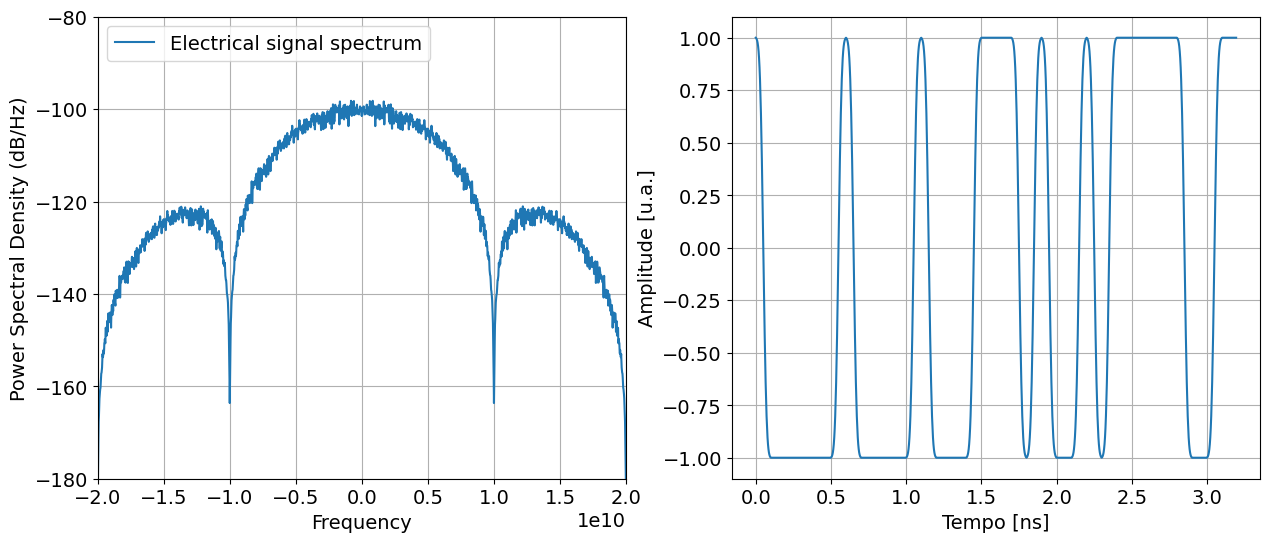

In [ ]:
#Lọc Định hình Xung & Vẽ Mật độ Phổ Công suất (PSD)
# pulse formatting
sigTx  = firFilter(pulse, symbolsUp)

# psd plot:  Đồ thị 1: Mật độ phổ công suất (Power Spectral Density - PSD)
fig, axs = plt.subplots(1, 2, figsize=(15,6))
axs[0].set_xlim(-2*Rs,2*Rs);
axs[0].set_ylim(-180,-80);
axs[0].psd(sigTx,Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'Electrical signal spectrum')
axs[0].legend(loc='upper left')
# Đồ thị 2: Dạng sóng tín hiệu điện NRZ trong miền thời gian
axs[1].plot(t[idX], sigTx[idX].real)
axs[1].set_xlabel('Tempo [ns]')
axs[1].set_ylabel('Amplitude [u.a.]')
axs[1].grid(True)

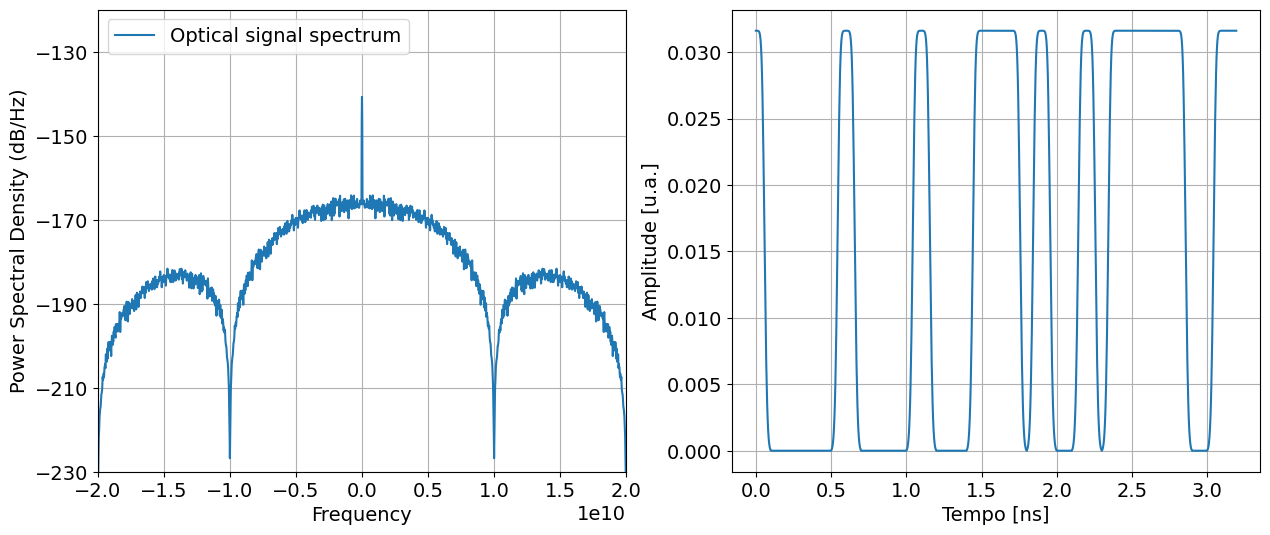

In [ ]:
# optical modulation: Điều chế tín hiệu quang (Optical Modulation)
Ai     = np.sqrt(Pi) # Biên độ trường quang ngõ vào MZM (Ai = sqrt(1 mW) ≈ 0.03162 sqrt(W))
paramMZM = parameters()
paramMZM.Vpi = Vπ #điện áp nửa bước sóng
paramMZM.Vb = Vb #điện áp phân cực 
sigTxo = mzm(Ai, sigTx, paramMZM) # Trường điện từ quang ngõ ra MZM (tín hiệu phía phát)

# Đồ thị 1: Mật độ phổ công suất quang (Optical PSD) tính theo công suất quang |sigTxo|^2
fig, axs = plt.subplots(1, 2, figsize=(15,6))
axs[0].set_xlim(-2*Rs,2*Rs);
axs[0].set_ylim(-230,-120);
axs[0].psd(np.abs(sigTxo)**2,Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'Optical signal spectrum')
axs[0].legend(loc='upper left')
# Đồ thị 2: Biên độ trường quang |sigTxo| theo thời gian
axs[1].plot(t[idX], np.abs(sigTxo[idX]))
axs[1].set_xlabel('Tempo [ns]')
axs[1].set_ylabel('Amplitude [u.a.]')
axs[1].grid(True)

In [ ]:
# Chuẩn bị biến đổi Fourier FFT cho tín hiệu phát
# optical transmission
NFFT = len(sigTxo) # Số điểm FFT = tổng số mẫu tín hiệu
sigTxoFFT = np.fft.fftshift(np.fft.fft(sigTxo))/NFFT # Phổ phổ trường quang phát
sigTxoPx  = np.abs(sigTxoFFT)**2 # Mật độ công suất phổ phát theo W
freq = np.fft.fftshift(np.fft.fftfreq(len(sigTxoFFT), Ta))

# Optical fiber: Mô hình Hàm truyền Sợi quang H(f) bao gồm Tán sắc GVD và Suy hao
H  = np.exp(1j*0.5*beta2*z*(2*np.pi*freq)**2)*np.exp(-0.5*alpha*z) # Channel transfer function
# Tín hiệu quang tại đầu thu (miền tần số và miền thời gian)
sigRxoFFT = H * sigTxoFFT # Nhân phổ phát với hàm truyền H(f)
sigRxoPx  = np.abs(sigRxoFFT)**2 # Mật độ công suất phổ thu
sigRxo = np.fft.ifft(sigRxoFFT)*NFFT # Biến đổi IFFT về miền thời gian để thu được trường quang sigRxo

Tx signal strength (in dBm) = -3.08 dBm
Rx signal power (in dBm) = -14.28 dBm


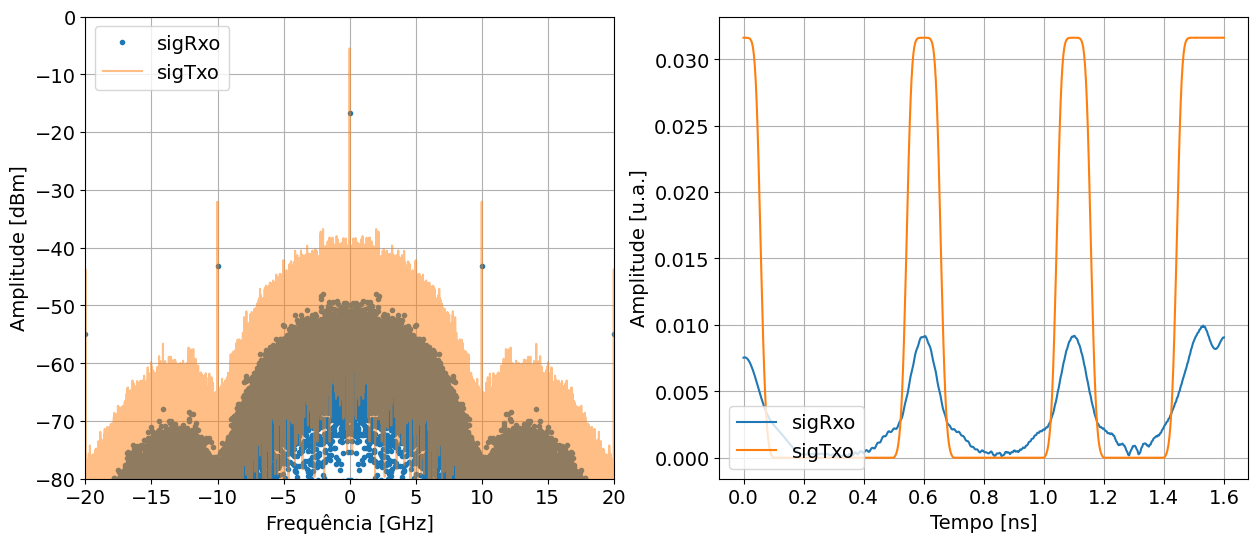

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15,6))
# Đồ thị 1: So sánh Phổ công suất Tín hiệu Phát (sigTxo) và Tín hiệu Thu (sigRxo)
axs[0].plot(1e-9*freq, 10*np.log10(1e3*sigRxoPx), '.', label = 'sigRxo')
axs[0].plot(1e-9*freq, 10*np.log10(1e3*sigTxoPx), alpha = 0.5, label = 'sigTxo')
axs[0].set_ylabel('Amplitude [dBm]')
axs[0].set_xlabel('Frequência [GHz]')
axs[0].set_xlim(-2e-9*Rs,2e-9*Rs)
axs[0].set_ylim(-80,0)
axs[0].grid(True)
axs[0].legend(loc = 'upper left')
# Đồ thị 2: So sánh Biên độ Trường quang Phát (sigTxo) và Thu (sigRxo) theo thời gian (1.6 ns)
axs[1].plot(t[0:513], abs(sigRxo[0:513]), label = 'sigRxo')
axs[1].plot(t[0:513], abs(sigTxo[0:513]), label = 'sigTxo')
axs[1].set_xlabel('Tempo [ns]')
axs[1].set_ylabel('Amplitude [u.a.]')
axs[1].grid(True)
axs[1].legend(loc = 'lower left')
#In kết quả Công suất tổng tín hiệu Phát và Thu
print('Tx signal strength (in dBm) = %.2f dBm' %(10*np.log10(np.sum(sigTxoPx)/1e-3)))
print('Rx signal power (in dBm) = %.2f dBm' %(10*np.log10(np.sum(sigRxoPx)/1e-3)))

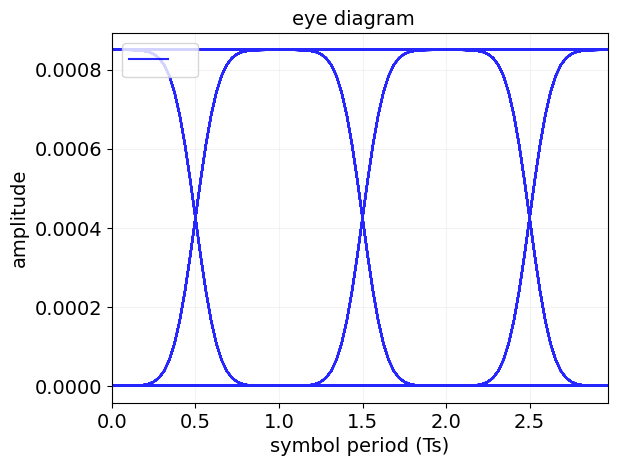

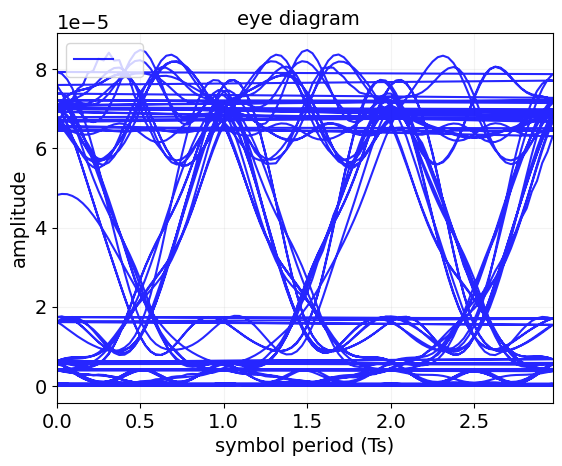

In [ ]:
# Optical signal reception
Nsamples = 2**12 # Số lượng mẫu lấy để dựng biểu đồ mắt (4096 mẫu)

# noise free photocurrent: Dòng điện quang thu được không tính đến nhiễu (noise-free):
Ip   = Rd*np.abs(sigTxo)**2 # Dòng điện quang tại ngõ phát (chuẩn hóa z = 0 km)
I_Rx = Rd*np.abs(sigRxo)**2 # Dòng điện quang tại ngõ thu (sau z = 70 km sợi quang)

# eye diagram
eyediagram(Ip,  Nsamples, SpS) # Biểu đồ mắt tín hiệu phát (Ip)
eyediagram(I_Rx, Nsamples, SpS) # Biểu đồ mắt tín hiệu thu (I_Rx)